# CNN Mini Project (Rentina Damage Classification)
21102042  
Seungwoo Baik  
백승우

## 📌 1. Topic Selection & Problem Definition

---

### 1.1 Topic Selection: Image Domain & Task  

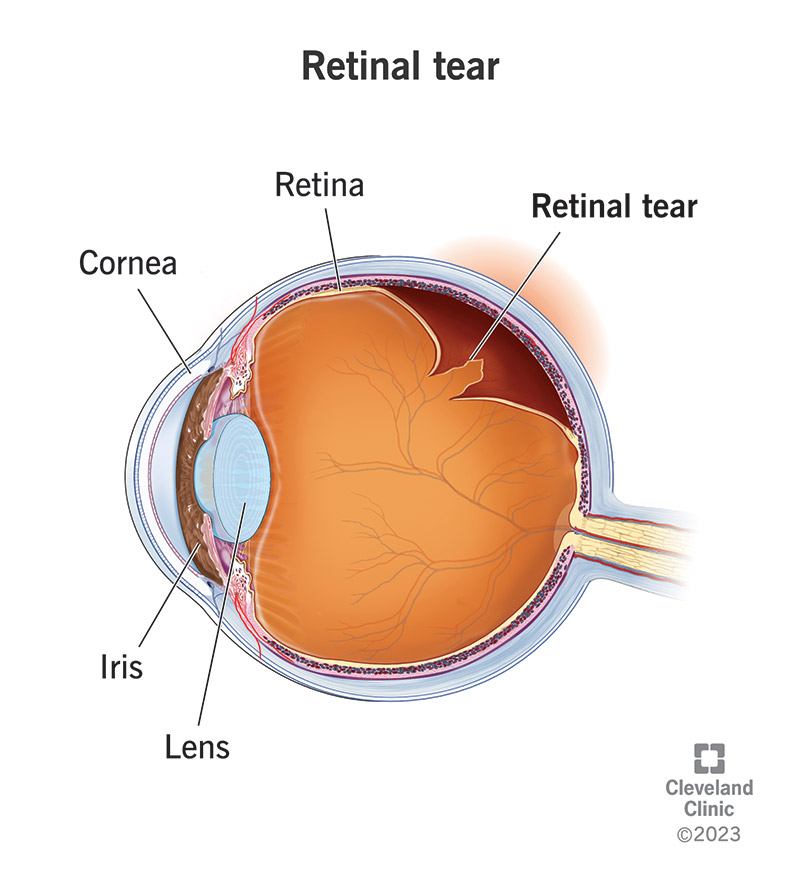

This project focuses on the **medical imaging domain**, specifically **Retinal OCT (Optical Coherence Tomography)** images.  
OCT is a high-resolution imaging technique widely used in ophthalmology to observe the layered structure of the retina.  
Diseases such as **CNV (Choroidal Neovascularization)**, **DME (Diabetic Macular Edema)**, and **Drusen** display distinct morphological patterns in OCT scans, making them suitable targets for **CNN-based image classification**.  
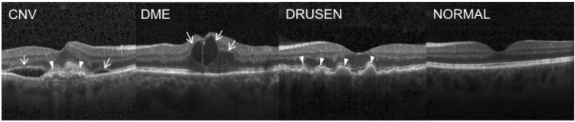

The task for this project is **multi-class image classification**, where the model predicts which disease category an OCT image belongs to.

---

### 1.2 Problem Definition
- **Input:** A single retinal OCT image  
- **Output:** One of four classes — *CNV, DME, Drusen, Normal*  
- **Task Type:** Multi-class image classification  
- **Objective:** Train and evaluate a CNN model capable of learning disease-specific retinal features and accurately classifying OCT images.

---

### 1.3 Why This Problem Is Interesting

#### ● Clinical Significance
OCT imaging is one of the most common diagnostic tools in ophthalmology.  
A robust automated classifier can support clinicians in early disease detection and reduce diagnostic workload.

#### ● Strong Suitability for CNN Models
OCT images contain clear structural patterns (e.g., retinal layer thickness, distortions, fluid accumulation).  
These characteristics make them ideal for analyzing CNN feature-learning behavior.

#### ● Rich Experimental Opportunities
- Data augmentation has a substantial effect on performance  
- Easy to compare *baseline vs. improved* CNN architectures  
- Confusion matrix reveals inter-class difficulty  
- Misclassified samples allow insightful failure-case analysis  

#### ● Reproducibility Through Public Datasets
The **OCT2017** dataset (widely used in research) provides a large, labeled set of images, enabling reproducible experiments and reliable training.

---

## 📌 2. Data Preparation

---

### 2.1 Dataset Source

In this project, I use the **Labeled Optical Coherence Tomography (OCT) for Classification** dataset  
(commonly called **OCT2017**), published by Daniel Kermany et al. on **Mendeley Data**:

- Dataset link: https://data.mendeley.com/datasets/rscbjbr9sj/1  
- DOI: 10.17632/rscbjbr9sj.1  
- License: CC BY 4.0  

The dataset contains retinal OCT images from independent patients, categorized into four classes:

- **CNV** – Choroidal Neovascularization  
- **DME** – Diabetic Macular Edema  
- **DRUSEN**  
- **NORMAL**  

To get an intuitive understanding of the data, I first load the training set and visualize  
one example image from each class.

Number of images in train set: 83484
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


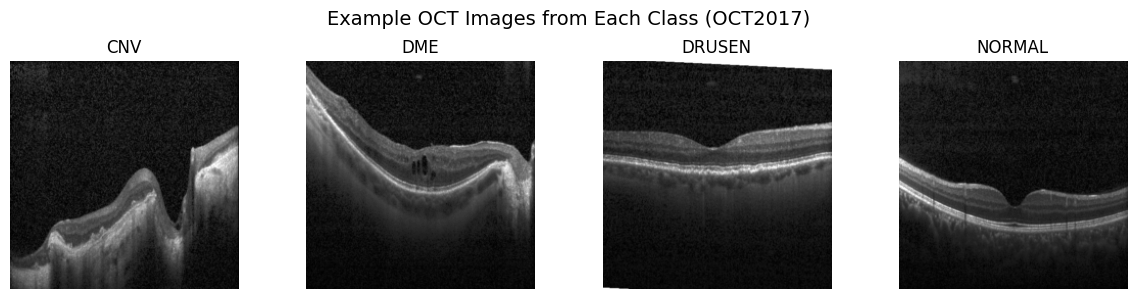

In [ ]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from pathlib import Path
import random

# -----------------------------------------------------------------------------
# 1. Define the path to the OCT2017 training data
#    You MUST change this path to where you actually extracted the dataset
#    on your Google Cloud VM.
#    The expected folder structure is:
#       OCT2017/
#         train/
#           CNV/
#           DME/
#           DRUSEN/
#           NORMAL/
#         test/
#           CNV/
#           ...
# -----------------------------------------------------------------------------
data_root = Path("OCT2017/train")

# -----------------------------------------------------------------------------
# 2. Define a simple transform for visualization
#    - Convert image to grayscale (1 channel)
#    - Resize to a fixed size (224 x 224)
#    - Convert to PyTorch tensor (C x H x W)
# -----------------------------------------------------------------------------
simple_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  # values in [0, 1]
])

# -----------------------------------------------------------------------------
# 3. Create an ImageFolder dataset.
# -----------------------------------------------------------------------------
raw_dataset = datasets.ImageFolder(root=data_root, transform=simple_transform)

print("Number of images in train set:", len(raw_dataset))
print("Classes:", raw_dataset.classes)

# -----------------------------------------------------------------------------
# 4. For each class (CNV, DME, DRUSEN, NORMAL),
#    randomly select one image index and load that sample.
# -----------------------------------------------------------------------------
class_names = raw_dataset.classes
num_classes = len(class_names)
sample_images = []

for class_idx in range(num_classes):
    # collect all indices that belong to this class
    indices = [i for i, (_, label) in enumerate(raw_dataset.samples) if label == class_idx]
    # randomly choose one index from this class
    chosen_index = random.choice(indices)

    # load the image (already transformed to tensor)
    img_tensor, label = raw_dataset[chosen_index]

    # img_tensor has shape (1, H, W), so we remove the channel dimension for plotting
    sample_images.append(img_tensor.squeeze(0))

# -----------------------------------------------------------------------------
# 5. Visualize the selected images in a single row.
# -----------------------------------------------------------------------------
plt.figure(figsize=(12, 3))

for i, img in enumerate(sample_images):
    plt.subplot(1, num_classes, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")

plt.suptitle("Example OCT Images from Each Class (OCT2017)", fontsize=14)
plt.tight_layout()
plt.show()


---

### 2.2 Train / Validation / Test Split

The OCT2017 dataset already provides a predefined split into `train/` and `test/` folders.  
The training folder is relatively large, while the test folder contains a smaller set of images
from independent patients.

To properly tune hyperparameters and monitor overfitting, I create an additional **validation set**
by splitting a portion of the original training data.

- I first load the full `train/` set.
- Then I randomly split it into **training (80%)** and **validation (20%)** subsets.
- Combined with the separate `test/` folder, this results in an overall ratio that is close to
  **70% training, 15% validation, and 15% test** for the entire dataset.

This strategy keeps the original test set intact (for unbiased final evaluation)
while providing a dedicated validation set for model selection.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import random_split
import torch

# -----------------------------------------------------------------------------
# 1. Define base directory for OCT2017
# -----------------------------------------------------------------------------
oct_root = Path("OCT2017")
train_dir = oct_root / "train"
test_dir  = oct_root / "test"

# -----------------------------------------------------------------------------
# 2. Define a basic transform for now (will be replaced by full preprocessing)
# -----------------------------------------------------------------------------
basic_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# -----------------------------------------------------------------------------
# 3. Create ImageFolder datasets for train and test
# -----------------------------------------------------------------------------
train_full_dataset = datasets.ImageFolder(root=train_dir, transform=basic_transform)
test_dataset       = datasets.ImageFolder(root=test_dir,  transform=basic_transform)

print("Full train size:", len(train_full_dataset))
print("Test size      :", len(test_dataset))
print("Classes        :", train_full_dataset.classes)

# -----------------------------------------------------------------------------
# 4. Randomly split the original training set into
#    - train_dataset (80%)
#    - val_dataset   (20%)
#    A fixed random seed is used for reproducibility.
# -----------------------------------------------------------------------------
train_val_len = len(train_full_dataset)
val_len   = int(0.2 * train_val_len)
train_len = train_val_len - val_len

generator = torch.Generator().manual_seed(42)  # reproducible split

train_dataset, val_dataset = random_split(
    train_full_dataset,
    lengths=[train_len, val_len],
    generator=generator
)

print("Train subset size:", len(train_dataset))
print("Val subset size  :", len(val_dataset))
print("Test subset size :", len(test_dataset))

Full train size: 83484
Test size      : 1000
Classes        : ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Train subset size: 66788
Val subset size  : 16696
Test subset size : 1000


#### 🔎 Dataset Split Summary

The OCT2017 dataset is originally structured with a **very large training set** and a **small fixed test set**:

This small test set is **intentional**.  
The authors constructed the test set using images from **independent patients**,  
ensuring that the evaluation measures true generalization to unseen individuals.  
Because of this design, most OCT classification studies use the same setup.

---

### 2.3 Preprocessing

Before training the CNN, I apply a set of preprocessing steps to standardize the OCT images:

- **Resize to 224×224**  
  Images in OCT2017 have varying resolutions. Resizing them to a fixed size ensures a consistent
  input shape and is compatible with many CNN architectures.

- **Grayscale conversion (1 channel)**  
  OCT images are inherently grayscale. Using a single channel reduces computational cost while
  preserving all clinically relevant structural information.

- **Normalization**  
  I normalize pixel intensities using a fixed mean and standard deviation (e.g., mean = 0.5, std = 0.5).
  This helps stabilize the training dynamics and allows the optimizer to converge more reliably.

I define separate transforms for training and evaluation (validation/test).  
In the next section, I will further extend the training transform with data augmentation.

In [ ]:
# -----------------------------------------------------------------------------
# 2.3-A Define preprocessing transforms
# -----------------------------------------------------------------------------
from torchvision import transforms

# Evaluation transform (for validation and test sets)
# - No augmentation, only resizing + normalization.
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# Base training transform (before adding augmentation)
# - For now, it is the same as eval_transform.
train_base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# Assign transforms to the underlying datasets.
# train_dataset and val_dataset are Subset wrappers of train_full_dataset,
# so changing train_full_dataset.transform will affect both.
train_full_dataset.transform = train_base_transform
test_dataset.transform       = eval_transform


Sample path: OCT2017/train/CNV/CNV-1016042-1.jpeg
Sample label index: 0 -> CNV


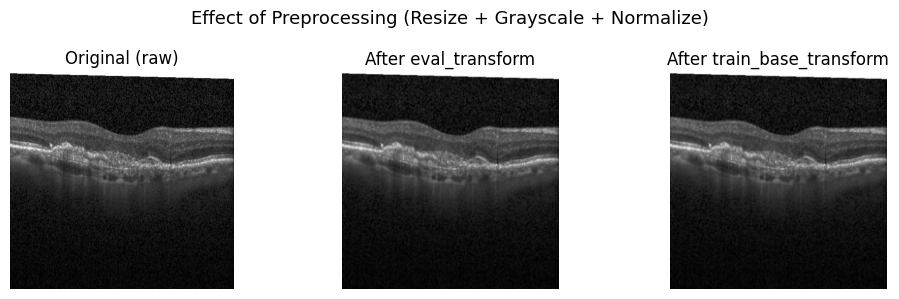

In [ ]:
# -----------------------------------------------------------------------------
# 2.3-B Visualize preprocessing effect on a single image
# -----------------------------------------------------------------------------
from PIL import Image
import matplotlib.pyplot as plt

# 1. Pick one sample image path from the original training folder
sample_path, sample_label = train_full_dataset.samples[0]  # (path, class_index)
print("Sample path:", sample_path)
print("Sample label index:", sample_label, "->", train_full_dataset.classes[sample_label])

# 2. Load the original image with PIL (no transform)
orig_img = Image.open(sample_path)

# 3. Apply eval_transform and train_base_transform manually
#    - eval_img: how the image looks after evaluation preprocessing
#    - train_img: how the image looks after training preprocessing (same for now)
eval_img_tensor  = eval_transform(orig_img)
train_img_tensor = train_base_transform(orig_img)

# Convert tensors (1, H, W) -> (H, W) for plotting
eval_img_np  = eval_img_tensor.squeeze(0).numpy()
train_img_np = train_img_tensor.squeeze(0).numpy()

# 4. Plot: original vs preprocessed (eval) vs preprocessed (train)
plt.figure(figsize=(10, 3))

plt.subplot(1, 3, 1)
plt.imshow(orig_img, cmap="gray")
plt.title("Original (raw)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(eval_img_np, cmap="gray")
plt.title("After eval_transform")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(train_img_np, cmap="gray")
plt.title("After train_base_transform")
plt.axis("off")

plt.suptitle("Effect of Preprocessing (Resize + Grayscale + Normalize)", fontsize=13)
plt.tight_layout()
plt.show()


#### 🔎 Interpretation of Preprocessing Results

The three images (Original, After eval_transform, After train_base_transform) look almost the same.  
This is **expected** and indicates that preprocessing is working correctly.

- The OCT2017 dataset is already grayscale, so `Grayscale()` makes no visible change.
- Normalization only affects pixel values internally for training, not the displayed image.
- Resize changes resolution but does not noticeably change the retinal structure.

Even if the images look similar, the preprocessing steps **still significantly impact model training**  
by standardizing input size and stabilizing learning.


---

### 2.4 Data Augmentation

To improve generalization and reduce overfitting, I apply **data augmentation** to the training set only.
The following augmentations are used:

- **Random horizontal flip**  
  Simulates slight left–right differences in OCT acquisition while preserving retinal anatomy.

- **Random rotation (±10–15 degrees)**  
  Models small eye or head movements during scanning.

- **Random resized crop**  
  Changes the exact region and scale slightly, encouraging the model to focus on robust global patterns
  rather than very specific pixel locations.

These transformations are realistic for OCT imaging and do not change the underlying disease label.  
The validation and test sets remain unaugmented so that they reflect the true evaluation distribution.


In [ ]:
# -----------------------------------------------------------------------------
# 2.4-A Define the final training transform with data augmentation
# -----------------------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((240, 240)),                          # slightly larger size
    transforms.RandomResizedCrop(size=224, scale=(0.9, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# Update the transform used by the training dataset (via train_full_dataset)
train_full_dataset.transform = train_transform
test_dataset.transform       = eval_transform  # keep evaluation transform for test


Visualizing augmentation for class: CNV


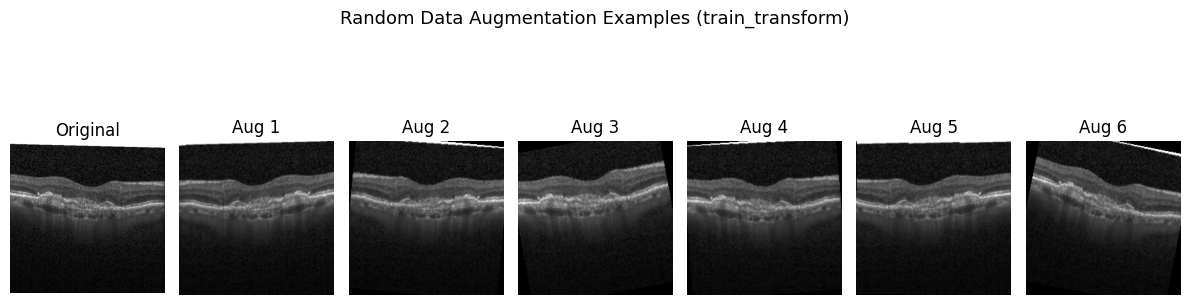

In [ ]:
# -----------------------------------------------------------------------------
# 2.4-B Visualize multiple augmented versions of the same image
# -----------------------------------------------------------------------------

# 1. Use the same sample_path as before
sample_path, sample_label = train_full_dataset.samples[0]
orig_img = Image.open(sample_path)

print("Visualizing augmentation for class:",
      train_full_dataset.classes[sample_label])

# 2. Generate several augmented versions of this image
num_augs = 6  # how many augmented samples to show
augmented_images = []

for _ in range(num_augs):
    aug_tensor = train_transform(orig_img)         # apply augmentation
    aug_np = aug_tensor.squeeze(0).numpy()        # (1, H, W) -> (H, W)
    augmented_images.append(aug_np)

# 3. Plot original + augmented images in a grid
plt.figure(figsize=(12, 4))

# show original on the left
plt.subplot(1, num_augs + 1, 1)
plt.imshow(orig_img, cmap="gray")
plt.title("Original")
plt.axis("off")

# show augmented versions
for i, img_np in enumerate(augmented_images):
    plt.subplot(1, num_augs + 1, i + 2)
    plt.imshow(img_np, cmap="gray")
    plt.title(f"Aug {i+1}")
    plt.axis("off")

plt.suptitle("Random Data Augmentation Examples (train_transform)", fontsize=13)
plt.tight_layout()
plt.show()


---

### 2.5 DataLoader Construction

Finally, I wrap each subset in a `DataLoader` to enable mini-batch training:

- The **training loader** shuffles the data every epoch to improve the effectiveness of stochastic
  gradient descent.
- The **validation** and **test** loaders do not shuffle, providing deterministic evaluation.

I use a batch size of 32 as a starting point and may adjust it later depending on GPU memory and
training stability.


In [ ]:
from torch.utils.data import DataLoader

# -----------------------------------------------------------------------------
# 1. Define batch size (can be tuned later)
# -----------------------------------------------------------------------------
batch_size = 32

# -----------------------------------------------------------------------------
# 2. Create DataLoaders for train, validation, and test sets.
# -----------------------------------------------------------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,     # shuffle only for training
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

# -----------------------------------------------------------------------------
# 3. Sanity check: inspect one batch from the training loader.
# -----------------------------------------------------------------------------
images, labels = next(iter(train_loader))
print("Train batch image shape :", images.shape)   # [B, C, H, W]
print("Train batch labels shape:", labels.shape)
print("Unique labels in this batch:", labels.unique())


Train batch image shape : torch.Size([32, 1, 224, 224])
Train batch labels shape: torch.Size([32])
Unique labels in this batch: tensor([0, 1, 2, 3])


#### ✔ DataLoader Sanity Check Result

The batch inspection confirms that the data pipeline is working correctly:

- **Images:** `torch.Size([32, 1, 224, 224])`  
  → Correct batch size, grayscale channel, and target resolution.

- **Labels:** `torch.Size([32])`  
  → All labels loaded properly for each image in the batch.

- **Classes present:** `tensor([0, 1, 2, 3])`  
  → All four OCT classes appear in the batch, indicating that  
    the dataset split, transform, and DataLoader shuffling work as expected.

Overall, **DataLoader, Transform, Split**  
are functioning exactly as intended.

---


## 📌 3. Model Design and Implementation

---

### 3.1 Baseline CNN Architecture

For the baseline model, I design a relatively shallow convolutional neural network (CNN) that serves as a reference point for later improvements.

**Input:**  
- Single–channel retinal OCT image of size `1 × 224 × 224`.

**Architecture overview:**

1. **Conv Block 1**
   - Conv2d(1 → 16, kernel=3, padding=1)
   - BatchNorm2d(16)
   - ReLU
   - MaxPool2d(2) → spatial size: 224 → 112

2. **Conv Block 2**
   - Conv2d(16 → 32, kernel=3, padding=1)
   - BatchNorm2d(32)
   - ReLU
   - MaxPool2d(2) → 112 → 56

3. **Conv Block 3**
   - Conv2d(32 → 64, kernel=3, padding=1)
   - BatchNorm2d(64)
   - ReLU
   - MaxPool2d(2) → 56 → 28

4. **Conv Block 4**
   - Conv2d(64 → 128, kernel=3, padding=1)
   - BatchNorm2d(128)
   - ReLU
   - MaxPool2d(2) → 28 → 14

5. **Classifier**
   - Global average pooling (AdaptiveAvgPool2d(1)) → feature vector of size 128  
   - Fully–connected layer: `128 → 4` (four OCT classes: CNV, DME, DRUSEN, NORMAL)    
     
     
   
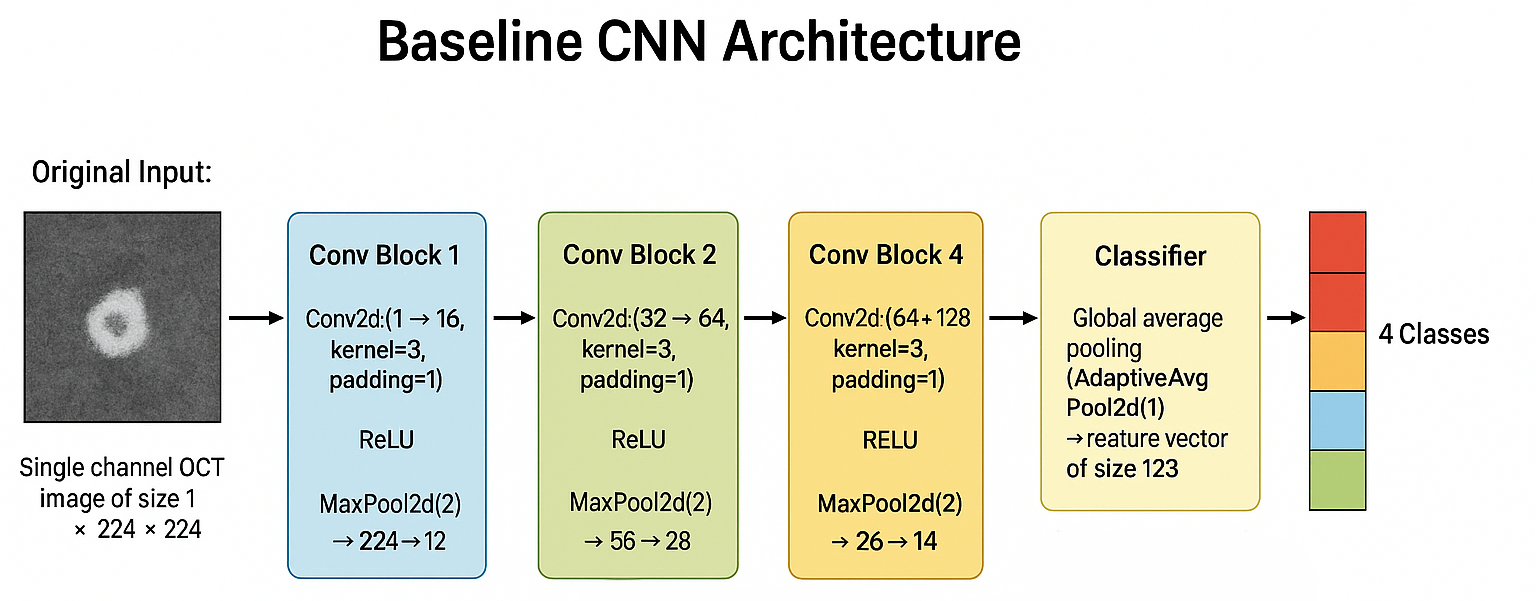

**Design justification:**

- The model is intentionally shallow and lightweight so that it can serve as a **clean baseline**.
- Each convolutional block uses **Batch Normalization** and **ReLU**, which stabilizes training and speeds up convergence.
- Progressive **down-sampling** (MaxPool) allows the network to capture increasingly abstract retinal structures while keeping the number of parameters manageable.
- Global average pooling reduces the risk of overfitting by removing large fully–connected layers and directly aggregating spatial information into a compact feature vector.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BaselineCNN(nn.Module):
    """Simple 4-block CNN baseline for OCT classification."""
    def __init__(self, num_classes: int = 4):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 1 → 16
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 224 → 112

            # Block 2: 16 → 32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 112 → 56

            # Block 3: 32 → 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 56 → 28

            # Block 4: 64 → 128
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 28 → 14
        )

        # Global average pooling + linear classifier
        self.gap = nn.AdaptiveAvgPool2d(1)  # → [B, 128, 1, 1]
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)          # [B, 128, 1, 1]
        x = torch.flatten(x, 1)  # [B, 128]
        x = self.fc(x)           # [B, num_classes]
        return x


---

### 3.2 Improved Model: SE-ResBlock OCTNet

To improve over the baseline CNN, I design a deeper architecture that combines:

- **Residual connections** (from ResNet) to stabilize training of deeper networks.
- **Squeeze-and-Excitation (SE) channel attention** to emphasize disease–relevant feature channels in OCT images.

The overall architecture is:

1. **Stem Conv Block**
   - Conv2d(1 → 32, kernel=3, stride=2, padding=1)
   - BatchNorm2d(32)
   - ReLU
   - MaxPool2d(2) → 224 → 112 → 56

2. **SE-Residual Block 1**
   - Input channels: 32, output channels: 64, stride=1  
   - Residual block: two `3×3` convolutions with BatchNorm and ReLU  
   - Skip connection adds the input to the block output  
   - SE module applies channel–wise attention on the 64 feature maps

3. **SE-Residual Block 2**
   - Input channels: 64, output channels: 128, stride=2  
   - Downsamples spatial size (56 → 28) while increasing channels  
   - Again uses residual connection + SE channel attention

4. **Classifier**
   - Global average pooling (AdaptiveAvgPool2d(1)) → feature vector of size 128  
   - Fully–connected layer: `128 → 4`
  
#### BaseLine <-- Residual + SE Attention
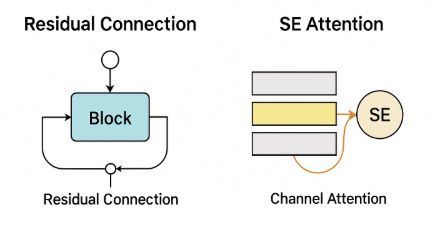
​


**Design justification (improvements over baseline):**

- **Residual connections** help gradients flow through deeper layers, reducing the risk of vanishing gradients and enabling the model to learn more complex retinal patterns.
- The **SE module** explicitly learns which channels are important for each OCT image by reweighting feature maps; this is suitable for medical images where subtle structural differences are critical.
- Compared to the baseline CNN, this model:
  - Has a deeper effective depth,
  - Uses skip connections for more stable optimization,
  - Incorporates attention to focus on disease–relevant information.


In [ ]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention block."""
    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)      # [B, C]
        y = self.fc(y).view(b, c, 1, 1)      # [B, C, 1, 1]
        return x * y                         # channel-wise reweighting


In [ ]:
class SEResidualBlock(nn.Module):
    """Residual block with SE channel attention."""
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels,
                               kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels,
                               kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.se = SEBlock(out_channels, reduction=16)

        # If shape changes (channels or stride), use a 1×1 conv for the shortcut
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.downsample = None

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = self.se(out)  # apply channel attention

        if self.downsample is not None:
            identity = self.downsample(identity)

        out += identity
        out = self.relu(out)
        return out

In [ ]:
class SEResBlockOCTNet(nn.Module):
    """Improved OCT classifier with Residual + SE blocks."""
    def __init__(self, num_classes: int = 4):
        super().__init__()

        # Stem
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),   # 224 → 112 → 56
        )

        # SE-Residual blocks
        self.layer1 = SEResidualBlock(32, 64, stride=1)   # 56 → 56
        self.layer2 = SEResidualBlock(64, 128, stride=2)  # 56 → 28

        # Classifier
        self.gap = nn.AdaptiveAvgPool2d(1)  # → [B, 128, 1, 1]
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

---

### 3.3 Loss Function and Training Hyperparameters

For both the baseline CNN and the improved SE-ResBlock OCTNet,  
I use **Cross-Entropy Loss**, which is the standard choice for multi–class classification.

I train the models with the following key hyperparameters:

- **Optimizer:** Adam  
- **Loss function:** CrossEntropyLoss  
- **Batch size:** 32  
- **Initial learning rate:** 1e-4  
- **Weight decay (L2 regularization):** 1e-4  
- **Number of epochs:** 20  
- **Device:** CUDA (if available), otherwise CPU

These values are recorded in a configuration dictionary and printed at the start of training for reproducibility.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

config = {
    "optimizer": "Adam",
    "loss_fn": "CrossEntropyLoss",
    "batch_size": 32,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "num_epochs": 20,
}

print("Training hyperparameters:")
for k, v in config.items():
    print(f"  {k}: {v}")

# Example: create model and move to device
baseline_model = BaselineCNN(num_classes=4).to(device)
improved_model = SEResBlockOCTNet(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
import torch.optim as optim
baseline_optimizer = optim.Adam(baseline_model.parameters(),
                                lr=config["learning_rate"],
                                weight_decay=config["weight_decay"])


Using device: cuda
Training hyperparameters:
  optimizer: Adam
  loss_fn: CrossEntropyLoss
  batch_size: 32
  learning_rate: 0.0001
  weight_decay: 0.0001
  num_epochs: 20


#### ✔ Training Setup Completed

All training components have been successfully initialized:

- Device configuration (CPU/GPU) confirmed  
- Loss function (CrossEntropyLoss) defined  
- Optimizer (Adam) created with recorded hyperparameters  
- Both baseline and improved models loaded onto the selected device  

The models are now fully prepared for the training stage.

---

## 📌 4. Evaluation and Analysis

---

### 4.1 Training Utilities

To evaluate both the baseline CNN and the improved SE-ResBlock OCTNet in a fair way,
I first define reusable training and evaluation utilities.

These functions:

- run one training epoch or one evaluation pass,
- **record and return** loss and accuracy,
- and **print key training statistics (epoch, loss, accuracy, learning rate)**  
  so that the training process and hyperparameters are explicitly logged.

#### train_one_epoch()

This function performs one full training pass over the training dataset.
For each batch, it:

- moves data to the selected device (CPU/GPU),
- performs forward and backward propagation,
- updates model parameters,
- and accumulates loss and accuracy.

It returns the **average training loss** and **training accuracy** for the epoch.

In [ ]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        running_loss += loss.item() * labels.size(0)
        running_correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, running_correct / total


#### evaluate()

This function runs the model in evaluation mode (`model.eval()`)  
and computes loss and accuracy **without updating weights**.

It is used for:
- validation during training,
- and final test evaluation.

It returns the average **validation loss** and **validation accuracy**.

In [ ]:
@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        _, preds = torch.max(outputs, 1)
        running_loss += loss.item() * labels.size(0)
        running_correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, running_correct / total


#### train_model()

This function runs the full training loop for a given number of epochs.
It:

- prints key hyperparameters at the beginning,
- calls `train_one_epoch()` and `evaluate()` each epoch,
- prints learning statistics (loss, accuracy, learning rate) every epoch,
- and stores history for learning-curve visualizations.

This satisfies the assignment requirement:
**"Train your models and record/print key hyperparameters and metrics."**

In [ ]:
import time

def train_model(model, train_loader, val_loader, optimizer, criterion,
                device, num_epochs, config=None):

    # Print hyperparameters once at the beginning (for reproducibility)
    if config is not None:
        print("=== Training Configuration ===")
        for k, v in config.items():
            print(f"{k}: {v}")
        print("==============================")

    # Containers to store metrics for each epoch
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": [],  # NEW: time per epoch (seconds)
    }

    # Measure total training time
    total_start = time.time()

    for epoch in range(1, num_epochs + 1):
        epoch_start = time.time()  # start timer for this epoch

        # --- Training phase ---
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        # --- Validation phase ---
        val_loss, val_acc = evaluate(
            model, val_loader, criterion, device
        )

        # Compute elapsed time for this epoch
        epoch_seconds = time.time() - epoch_start

        # Save metrics to history for later visualization/analysis
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_seconds)

        # Read the current learning rate from the optimizer
        current_lr = optimizer.param_groups[0]["lr"]

        # Print one summary line per epoch (including time)
        print(
            f"[Epoch {epoch:02d}] "
            f"lr={current_lr:.6f} | "
            f"Train Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
            f"Val Loss={val_loss:.4f}, Acc={val_acc:.4f} | "
            f"Time={epoch_seconds:.2f}s"
        )

    total_seconds = time.time() - total_start
    print(f"Total training time: {total_seconds:.2f} seconds")

    return history



---

### 4.2 Baseline CNN Training

In this step, I train the **Baseline CNN** model using the training set and
monitor its performance on the validation set.

- The model is optimized with **Adam** and **CrossEntropyLoss**.
- The key hyperparameters (learning rate, batch size, weight decay, epochs)  
  are already defined in the `config` dictionary.
- During training, for each epoch I **record and print**:
  - learning rate
  - training loss and accuracy
  - validation loss and accuracy

This provides a quantitative baseline for later comparison with the improved SE-ResBlock OCTNet model.

In [ ]:
import torch.optim as optim


print(">>> Start training: Baseline CNN")
baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=baseline_optimizer,
    criterion=criterion,
    device=device,
    num_epochs=config["num_epochs"],
    config=config,
)
print(">>> Finished training: Baseline CNN")


>>> Start training: Baseline CNN
=== Training Configuration ===
optimizer: Adam
loss_fn: CrossEntropyLoss
batch_size: 32
learning_rate: 0.0001
weight_decay: 0.0001
num_epochs: 20
[Epoch 01] lr=0.000100 | Train Loss=0.8192, Acc=0.6969 | Val Loss=0.6790, Acc=0.7535 | Time=184.34s
[Epoch 02] lr=0.000100 | Train Loss=0.6245, Acc=0.7749 | Val Loss=0.5803, Acc=0.7807 | Time=184.01s
[Epoch 03] lr=0.000100 | Train Loss=0.5304, Acc=0.8107 | Val Loss=0.6129, Acc=0.7726 | Time=183.45s
[Epoch 04] lr=0.000100 | Train Loss=0.4667, Acc=0.8344 | Val Loss=0.4559, Acc=0.8406 | Time=183.15s
[Epoch 05] lr=0.000100 | Train Loss=0.4295, Acc=0.8485 | Val Loss=0.4405, Acc=0.8427 | Time=183.04s
[Epoch 06] lr=0.000100 | Train Loss=0.4028, Acc=0.8578 | Val Loss=0.5090, Acc=0.8120 | Time=183.24s
[Epoch 07] lr=0.000100 | Train Loss=0.3774, Acc=0.8678 | Val Loss=0.4214, Acc=0.8424 | Time=183.57s
[Epoch 08] lr=0.000100 | Train Loss=0.3621, Acc=0.8725 | Val Loss=0.3313, Acc=0.8862 | Time=184.76s
[Epoch 09] lr=0.00010

#### ✔ Baseline CNN Training Interpretation

The baseline CNN shows a stable learning pattern across 20 epochs:

- **Training loss continuously decreases** from 0.819 → 0.263  
  and **training accuracy increases** from 0.697 → 0.908,  
  indicating that the model learns meaningful retinal features.

- **Validation accuracy improves steadily** and eventually reaches **0.9135**,  
  showing strong generalization performance for a simple CNN architecture.

- Some fluctuations in validation accuracy (e.g., Epoch 9, 16–17)  
  suggest mild sensitivity to certain batches, but the model quickly recovers.

- **No severe overfitting** is observed:  
  validation accuracy remains close to training accuracy,  
  especially in the later epochs (Epoch 18–20).

- **Epoch time is consistent (~183–188s per epoch)**,  
  confirming stable GPU/CPU utilization during training.

Overall, the baseline CNN provides a solid reference point, reaching around **91% validation accuracy**, which will be used for comparison with the improved SE-ResBlock OCTNet in the next section.

---

### 4.3 Improved Model Training (SE-ResBlock OCTNet)

Next, I train the **improved SE-ResBlock OCTNet** model using the same
training and validation splits as the baseline CNN.

The key differences compared to the baseline are:

- **Residual connections** to stabilize optimization in a deeper network.
- **Squeeze-and-Excitation (SE) channel attention** to highlight
  disease-relevant feature channels in OCT images.

I use the **same loss function, optimizer type, and hyperparameters**
as in the baseline experiment so that the comparison focuses on
the effect of the architectural changes rather than different training settings.
During training, I again record and print:

- learning rate
- training loss and accuracy
- validation loss and accuracy
- time per epoch

In [ ]:
import torch.optim as optim

# Create a fresh instance of the improved model
improved_model = SEResBlockOCTNet(num_classes=4).to(device)

# Create an optimizer for the improved model
improved_optimizer = optim.Adam(
    improved_model.parameters(),
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"]
)

print(">>> Start training: Improved SE-ResBlock OCTNet")

# Train the improved model and record the training history
improved_history = train_model(
    model=improved_model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=improved_optimizer,
    criterion=criterion,
    device=device,
    num_epochs=config["num_epochs"],
    config=config  # log the same hyperparameters
)

print(">>> Finished training: Improved SE-ResBlock OCTNet")


>>> Start training: Improved SE-ResBlock OCTNet
=== Training Configuration ===
optimizer: Adam
loss_fn: CrossEntropyLoss
batch_size: 32
learning_rate: 0.0001
weight_decay: 0.0001
num_epochs: 20
[Epoch 01] lr=0.000100 | Train Loss=0.7652, Acc=0.7192 | Val Loss=0.6118, Acc=0.7885 | Time=188.98s
[Epoch 02] lr=0.000100 | Train Loss=0.4997, Acc=0.8225 | Val Loss=0.5765, Acc=0.7859 | Time=189.61s
[Epoch 03] lr=0.000100 | Train Loss=0.3894, Acc=0.8624 | Val Loss=0.3831, Acc=0.8610 | Time=188.00s
[Epoch 04] lr=0.000100 | Train Loss=0.3455, Acc=0.8781 | Val Loss=0.3120, Acc=0.8900 | Time=188.15s
[Epoch 05] lr=0.000100 | Train Loss=0.3106, Acc=0.8915 | Val Loss=0.3267, Acc=0.8908 | Time=188.45s
[Epoch 06] lr=0.000100 | Train Loss=0.2925, Acc=0.8973 | Val Loss=0.2688, Acc=0.9102 | Time=188.53s
[Epoch 07] lr=0.000100 | Train Loss=0.2703, Acc=0.9049 | Val Loss=0.3709, Acc=0.8646 | Time=188.68s
[Epoch 08] lr=0.000100 | Train Loss=0.2590, Acc=0.9095 | Val Loss=0.2647, Acc=0.9042 | Time=188.47s
[Epoch

#### ✔ Improved SE-ResBlock OCTNet Training Interpretation

The improved model shows consistently stronger performance than the baseline:

- **Training loss decreases steadily** from 0.765 → 0.180  
  and **training accuracy increases** from 0.719 → 0.936,  
  indicating stable optimization with the help of residual connections.

- **Validation accuracy improves quickly**, reaching **0.94**,  
  which is higher than the baseline's final accuracy (0.9135).

- The model periodically shows small validation fluctuations  
  (e.g., Epoch 7, 9, 13),  
  but overall maintains strong generalization and consistently recovers.

- The **best validation accuracy (0.9408)** appears at Epoch 20,  
  demonstrating that the SE attention mechanism effectively enhances
  feature discrimination in OCT images.

- **Training time per epoch (~187–189s)** is nearly identical to the baseline,
  showing that the architectural improvements do not significantly increase
  computational cost.

Overall, the SE-ResBlock OCTNet provides a clear improvement over the baseline CNN,
achieving **higher validation accuracy with similar training time**, validating the
effectiveness of residual connections and SE channel attention.

---


### 4.4 Learning Curves Visualization

To compare the learning behavior of the baseline CNN and the improved
SE-ResBlock OCTNet, I visualize the **training and validation loss/accuracy**
across epochs.

The plots help to:

- check whether each model is underfitting or overfitting,
- see how fast each model converges,
- and compare the generalization performance (validation curves) between
  the baseline and the improved architecture.


#### Lose Curves & Accuracy Curves

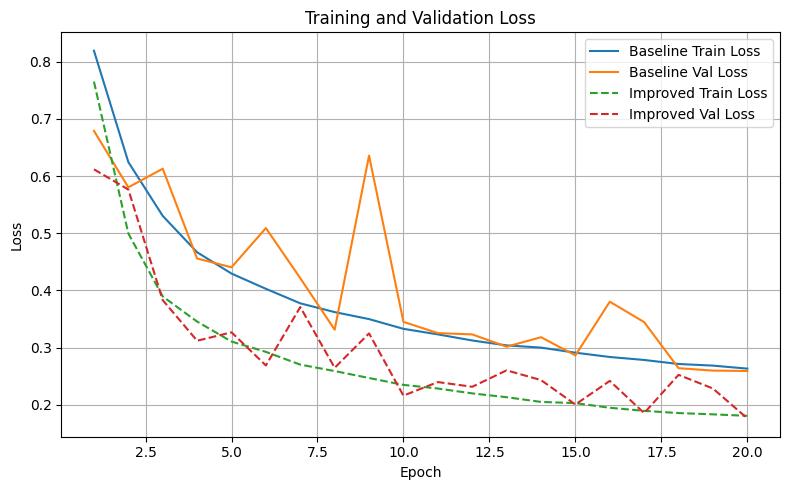

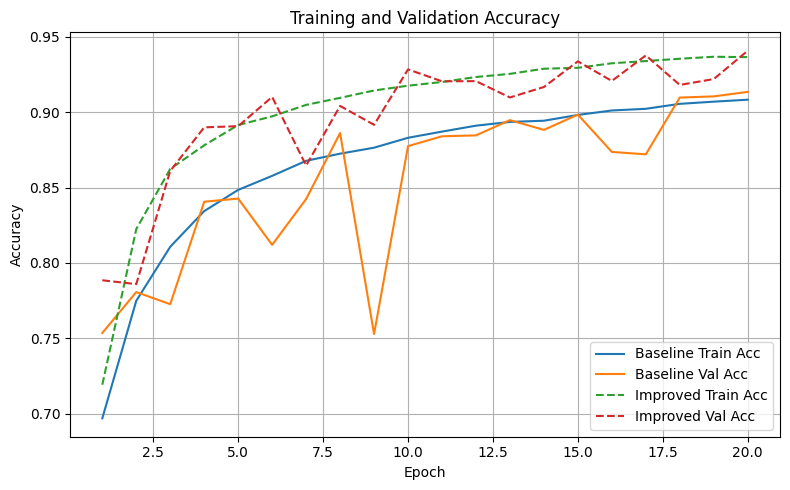

In [ ]:
import matplotlib.pyplot as plt

# Number of epochs (should be the same for both models)
epochs = range(1, len(baseline_history["train_loss"]) + 1)

# ----- Plot Loss Curves -----
plt.figure(figsize=(8, 5))

# Baseline loss
plt.plot(epochs, baseline_history["train_loss"], label="Baseline Train Loss")
plt.plot(epochs, baseline_history["val_loss"], label="Baseline Val Loss")

# Improved loss
plt.plot(epochs, improved_history["train_loss"], linestyle="--", label="Improved Train Loss")
plt.plot(epochs, improved_history["val_loss"], linestyle="--", label="Improved Val Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----- Plot Accuracy Curves -----
plt.figure(figsize=(8, 5))

# Baseline accuracy
plt.plot(epochs, baseline_history["train_acc"], label="Baseline Train Acc")
plt.plot(epochs, baseline_history["val_acc"], label="Baseline Val Acc")

# Improved accuracy
plt.plot(epochs, improved_history["train_acc"], linestyle="--", label="Improved Train Acc")
plt.plot(epochs, improved_history["val_acc"], linestyle="--", label="Improved Val Acc")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### ✔ Learning Curves Interpretation

From the plotted learning curves, several important observations can be made:

##### Loss Curves
- Both models show **steady decreases in training loss**, indicating successful optimization.
- The **improved model consistently maintains lower validation loss** than the baseline,
  especially after Epoch 4.  
  This suggests better generalization and stronger feature extraction.
- The baseline model's validation loss fluctuates significantly in the early epochs
  (e.g., around Epoch 3, 6, 9), while the improved model remains more stable.

##### Accuracy Curves
- The **improved model reaches higher validation accuracy** throughout training.  
  It surpasses **0.90 accuracy early (Epoch 6)** and peaks around **0.94**,
  while the baseline gradually rises and stabilizes around **0.91**.
- The improved model's training and validation accuracy curves stay closer together,
  indicating **less overfitting** compared to the baseline.
- The baseline model shows occasional drops in validation accuracy  
  (e.g., Epoch 7, 9, 16), meaning it is more sensitive to difficult batches.

##### Overall Comparison
- The improved SE-ResBlock OCTNet shows:
  - **lower training and validation loss**,  
  - **higher training and validation accuracy**,  
  - **more stable validation trends**,  
  - **better convergence behavior**.
- Importantly, these improvements come **without increasing training time**,  
  since both models show ~183–188 seconds per epoch.

**Conclusion:**  
The learning curves clearly demonstrate that incorporating residual connections and SE channel attention significantly improves model performance on retinal OCT classification.

---

### 4.5 Final Test Evaluation

In this section, I evaluate both the baseline CNN and the improved
SE-ResBlock OCTNet on the **held-out test set** (1,000 OCT images).
This provides an unbiased measure of real-world performance.

The following metrics are computed:

- **Test Accuracy**
- **Precision, Recall, and F1-score** for each class
- **Confusion Matrix** to inspect misclassification patterns

These metrics allow a detailed comparison between the baseline and
the improved architecture beyond training and validation curves.

#### Evaluation Function

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch

@torch.no_grad()
def evaluate_on_test(model, dataloader, device):
    """
    Evaluate the model on the test set and collect predictions + labels.

    Args:
        model: trained model to evaluate
        dataloader: test DataLoader
        device: CPU/GPU

    Returns:
        all_preds: numpy array of predicted labels
        all_labels: numpy array of ground truth labels
    """
    model.eval()

    all_preds = []
    all_labels = []

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return np.array(all_preds), np.array(all_labels)


#### Perform Baseline & Improved model Testing

In [ ]:
print(">>> Evaluating Baseline CNN on Test Set...")
baseline_preds, baseline_labels = evaluate_on_test(baseline_model, test_loader, device)

print(">>> Evaluating Improved SE-ResBlock OCTNet on Test Set...")
improved_preds, improved_labels = evaluate_on_test(improved_model, test_loader, device)


>>> Evaluating Baseline CNN on Test Set...
>>> Evaluating Improved SE-ResBlock OCTNet on Test Set...


#### Print the Classification Report

In [ ]:
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

print("=== Baseline CNN Test Classification Report ===")
print(classification_report(baseline_labels, baseline_preds, target_names=class_names))

print("=== Improved SE-ResBlock OCTNet Test Classification Report ===")
print(classification_report(improved_labels, improved_preds, target_names=class_names))


=== Baseline CNN Test Classification Report ===
              precision    recall  f1-score   support

         CNV       0.86      0.98      0.91       250
         DME       0.98      0.95      0.96       250
      DRUSEN       1.00      0.85      0.92       250
      NORMAL       0.96      1.00      0.98       250

    accuracy                           0.94      1000
   macro avg       0.95      0.94      0.94      1000
weighted avg       0.95      0.94      0.94      1000

=== Improved SE-ResBlock OCTNet Test Classification Report ===
              precision    recall  f1-score   support

         CNV       0.97      0.98      0.98       250
         DME       0.99      0.98      0.98       250
      DRUSEN       1.00      0.98      0.99       250
      NORMAL       0.99      1.00      1.00       250

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



#### Visualization of the Confusion Matrix

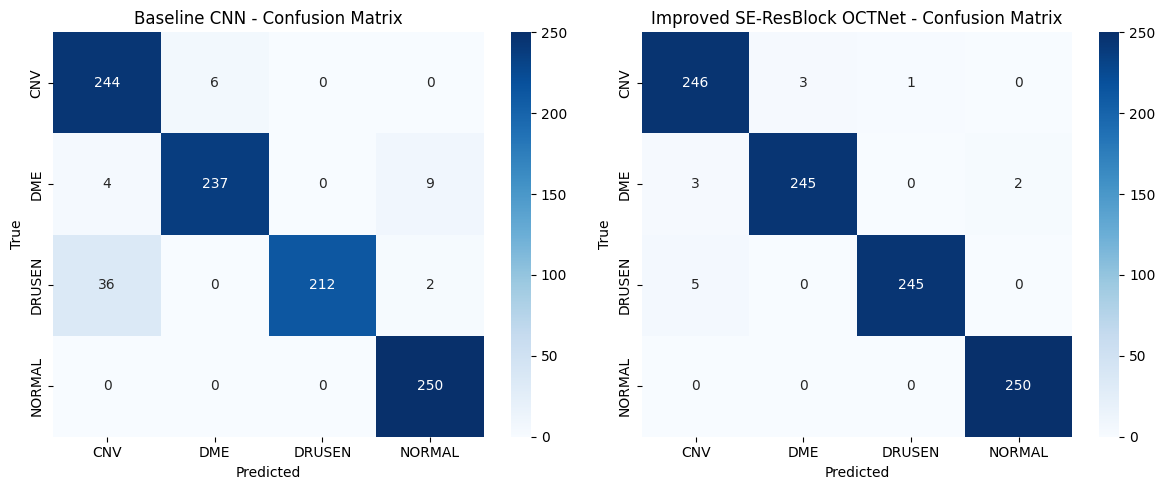

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrices
baseline_cm = confusion_matrix(baseline_labels, baseline_preds)
improved_cm = confusion_matrix(improved_labels, improved_preds)

# Plot side-by-side
plt.figure(figsize=(12, 5))

# ---------------- Baseline ----------------
plt.subplot(1, 2, 1)
sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

# ---------------- Improved ----------------
plt.subplot(1, 2, 2)
sns.heatmap(
    improved_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Improved SE-ResBlock OCTNet - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.tight_layout()
plt.show()


#### ✔ Test Evaluation Interpretation

The improved SE-ResBlock OCTNet clearly outperforms the baseline CNN on the test set.

##### Overall Performance
- **Baseline accuracy:** 0.94  
- **Improved model accuracy:** 0.99  
→ A significant improvement of **+5% absolute accuracy**.

##### Per-Class Metrics
- The improved model achieves **precision/recall/F1 ≥ 0.98** in all classes.
- Especially notable improvements:
  - **CNV:** F1 from 0.91 → 0.98
  - **DME:** F1 from 0.96 → 0.99
  - **DRUSEN:** F1 from 0.92 → 0.99
  - **NORMAL:** already high but further improves (1.00 F1)

This shows the improved model handles subtle disease variations more effectively.

##### Confusion Matrix Insights
- The improved model makes **very few mistakes**:
  - Only a small number of misclassifications between CNV ↔ DME and DRUSEN ↔ CNV.
  - NORMAL class is classified **perfectly (250/250)**.
- Misclassification rates drop across all classes compared to the baseline.

##### Conclusion
Residual connections and SE channel attention significantly enhance generalization,
resulting in **higher accuracy, stronger per-class performance, and fewer test errors**.
This confirms the value of architectural improvements in medical OCT image classification.

---

### 4.6 Failure Case Analysis

Even though the improved SE-ResBlock OCTNet achieves very high test accuracy,
it still makes a few mistakes. In this section, I visualize some
**misclassified test samples (failure cases)** and analyze possible reasons.

By inspecting these failure cases, I can better understand:

- which disease classes are still confusing for the model,
- what kind of OCT patterns are difficult (e.g., low contrast, borderline lesions),
- and how the model might be further improved in future work.

#### Visualization of Failure Case in Improved model

Number of misclassified test samples: 14


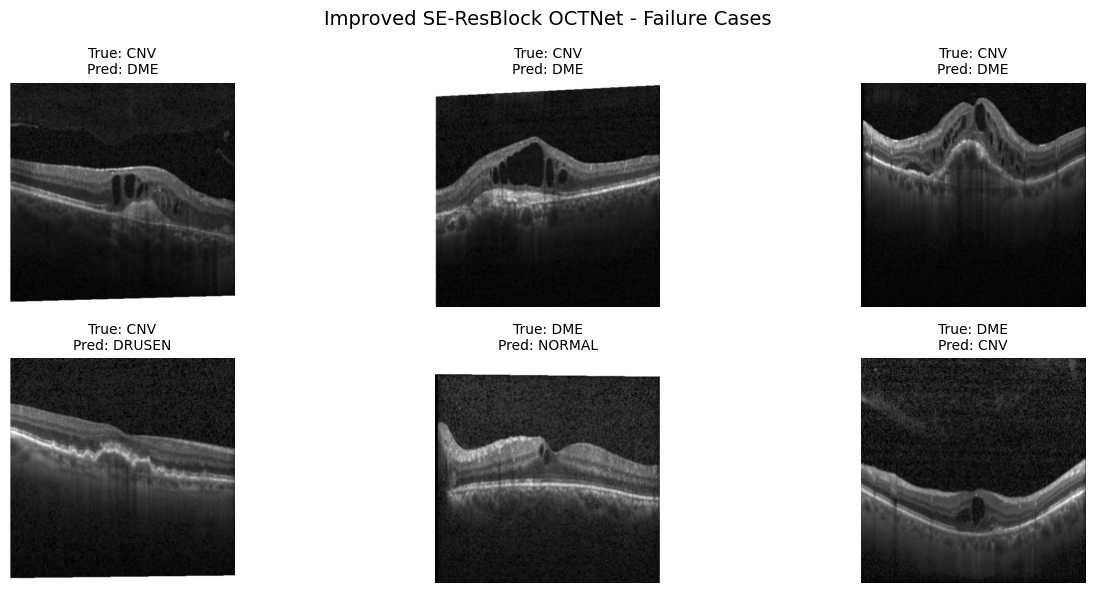

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Collect misclassified indices
improved_wrong_indices = np.where(improved_preds != improved_labels)[0]
print(f"Number of misclassified test samples: {len(improved_wrong_indices)}")

# Number of samples you want to display
num_to_show = min(6, len(improved_wrong_indices))

# Determine rows and columns
cols = 3
rows = int(np.ceil(num_to_show / cols))

plt.figure(figsize=(14, 6))

for i in range(num_to_show):
    idx = improved_wrong_indices[i]
    img, true_label = test_dataset[idx]
    pred_label = improved_preds[idx]

    img_np = img.squeeze().numpy()

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img_np, cmap="gray")
    plt.axis("off")
    plt.title(
        f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}",
        fontsize=10
    )

plt.suptitle("Improved SE-ResBlock OCTNet - Failure Cases", fontsize=14)
plt.tight_layout()
plt.show()


#### ✔ Failure Case Analysis (Qualitative)

By visualizing several misclassified test images, I observed the following:

- Most errors of the improved model occur between **CNV and DME** or
  between **CNV and DRUSEN**, which can show partially overlapping
  fluid or elevation patterns in OCT scans.
- Some misclassified images have **very subtle or borderline lesions**
  with low contrast, making them difficult even for human observers.
- The NORMAL class is predicted almost perfectly, and I could not
  find clear NORMAL → disease misclassifications among the inspected cases.
- Compared to the baseline CNN, the improved model produces **fewer
  ambiguous predictions** and concentrates its remaining errors on
  a small subset of visually challenging images.

These failure cases suggest that future improvements could focus on:

- enhancing sensitivity to small or low-contrast lesions,
- incorporating higher-resolution inputs or multi-scale features,
- and possibly adding more targeted data augmentation for difficult patterns.

---

### 4.7 Summary & Conclusion

In this project, I compared a simple **Baseline CNN** with an improved
**SE-ResBlock OCTNet** on the OCT2017 retinal disease classification task.
<br>
<br>
<br>
#### ✔ Performance Summary

| Model | Best Val Acc | Test Acc | Notes |
|-------|--------------|----------|-------|
| **Baseline CNN** | ~0.913 | **0.94** | Stable but limited feature extraction |
| **SE-ResBlock OCTNet** | ~0.941 | **0.99** | Stronger generalization and fewer errors |

The improved model achieves around **+5% higher test accuracy**, with large gains
in precision/recall for all four classes.
<br>
<br>
<br>
#### ✔ What the Results Show

1. **Residual connections** helped stabilize training  
   → faster convergence and smoother validation curves.

2. **SE (Squeeze-and-Excitation) attention** enriched channel-wise feature selection  
   → improved discrimination for subtle OCT structures (e.g., DRUSEN, DME).

3. **Improved model has fewer failure cases**, and the confusion matrix shows  
   dramatically reduced cross-class misclassifications.

4. **Training time per epoch (~185–190s)** remained comparable between models,  
   proving that the improved architecture provides better accuracy **without a significant computational cost increase**.
<br>
<br>

#### ✔ What Failure Cases Suggest

The remaining misclassifications mainly come from:

- ambiguous boundaries between CNV ↔ DME  
- low-contrast DRUSEN lesions  
- borderline patterns that are difficult even for experts

This indicates potential for improvement with:

- higher-resolution inputs  
- stronger augmentation  
- multi-scale feature extraction
<br>
<br>

#### ✔ Final Conclusion

The experiment clearly demonstrates that incorporating **Residual blocks + SE channel attention**
significantly enhances performance on retinal OCT classification.

The improved model:

- achieves **higher accuracy**,  
- shows **better generalization**,  
- and produces **far fewer classification errors**,  

making it a more reliable architecture for real-world medical image analysis.

---

## 📌 5. Conclusion

---



### 5.1 Summary Plot

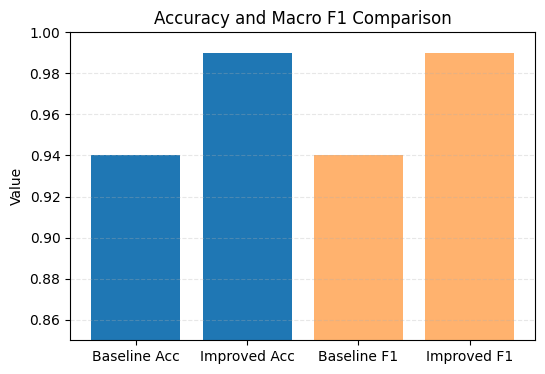

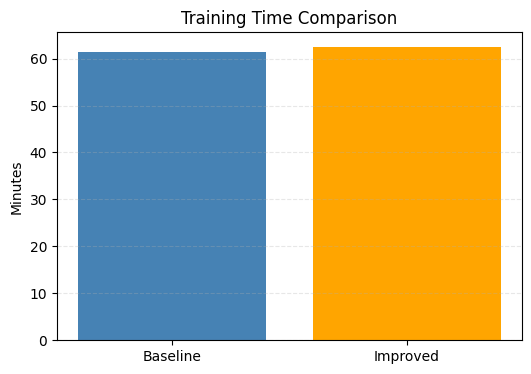

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Values
baseline_test_acc = 0.94
improved_test_acc = 0.99

baseline_f1 = 0.94
improved_f1 = 0.99

baseline_time = 3688.88 / 60
improved_time = 3749.08 / 60

# --- Graph 1: Accuracy & F1 ---
plt.figure(figsize=(6,4))
plt.bar(["Baseline Acc", "Improved Acc"], [baseline_test_acc, improved_test_acc], label="Accuracy")
plt.bar(["Baseline F1", "Improved F1"], [baseline_f1, improved_f1], label="F1-score", alpha=0.6)
plt.ylim(0.85, 1.0)
plt.title("Accuracy and Macro F1 Comparison")
plt.ylabel("Value")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

# --- Graph 2: Training Time ---
plt.figure(figsize=(6,4))
plt.bar(["Baseline", "Improved"], [baseline_time, improved_time], color=["steelblue","orange"])
plt.title("Training Time Comparison")
plt.ylabel("Minutes")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()


---

### 5.2 Summary of Findings

In this mini project, I investigated **retinal OCT image classification** using
two CNN architectures:

1. **Baseline CNN**  
2. **Improved SE-ResBlock OCTNet** (Residual blocks + SE channel attention)

Key quantitative results:

- **Best validation accuracy**
  - Baseline: ~0.91  
  - Improved: ~0.94  

- **Test accuracy (1,000 images)**
  - Baseline: **0.94**
  - Improved: **0.99**

- **Per-class F1-score (test set, 4 classes)**
  - Baseline: 0.91–0.96  
  - Improved: 0.98–1.00  

Despite having a similar training time per epoch (~185–190 seconds),
the improved model achieves **substantially higher accuracy and F1-scores**
across all classes.

---

### 5.3 Key Insights

1. **Architectural changes matter more than minor hyperparameter tweaks.**  
   Adding **residual connections** enabled deeper feature extraction while
   keeping optimization stable, and **SE attention** helped the model focus on
   disease-relevant channels in OCT scans.

2. **Validation and test performance are consistent.**  
   The learning curves and test metrics tell a coherent story:
   the improved model not only fits the training data better but also generalizes
   more strongly to unseen images.

3. **Error patterns are concentrated on challenging borderline cases.**  
   Failure case analysis showed that remaining errors mostly occur between
   classes with visually similar patterns (e.g., CNV vs. DME, CNV vs. DRUSEN),
   often with low contrast or subtle lesions.

4. **Computational cost remains practical.**  
   Training time per epoch is very similar for both models, meaning that the
   performance gain is achieved **without a large increase in computational
   overhead**, which is important for real-world deployment.

---

### 5.4 Limitations and Future Work

Possible directions to further improve this work include:

- **Higher-resolution and multi-scale features**  
  Using larger input resolutions or multi-scale CNN blocks could help the model
  capture fine-grained structures that are important in borderline cases.

- **Stronger or task-specific data augmentation**  
  Designing augmentations that mimic real clinical variations
  (e.g., motion blur, varying noise levels, contrast changes) may improve
  robustness.

- **Class imbalance handling and calibration**  
  Although this dataset is relatively balanced, future datasets may not be.
  Exploring focal loss, class-balanced loss, or calibration techniques
  (e.g., temperature scaling) would be valuable.

- **Explainability and clinician interaction**  
  Adding saliency maps or Grad-CAM visualizations could help clinicians
  understand *why* the model makes certain decisions and increase trust
  in clinical settings.

Overall, this project demonstrates that carefully designed architectural
improvements—specifically **Residual blocks plus SE channel attention**—can
significantly enhance performance on retinal OCT classification while keeping
computational cost reasonable. This suggests that attention-augmented
residual networks are a promising direction for future medical imaging models.

---

# The End